# 02 — Exploratory Data Analysis

**Data scope: training period only (2013-01-01 to 2013-08-31).** Feature design must not be
informed by validation (Sep–Oct) or test (Nov–Dec) outcomes, so every statistic below uses
January–August flights only. Validation is reserved for model selection; the Nov–Dec test
holdout is sealed and not present in the development data (`docs/decision_log.md`, D-002, D-101).

How does the probability of arriving ≥ 15 minutes late vary with airline, airport, route,
scheduled departure hour and month? Every grouping variable used here is **known before
departure**; the actual-time columns are used only to build the target.

Rates are shown with 95% Wilson confidence intervals and sample sizes so small groups are not
over-read. The dashed line in bar charts is the overall delay rate. Data: labelled flights after
the missing-label policy from `configs/config.yaml` (see `01_data_quality.ipynb`).

**Prediction scope.** The target is `is_delayed = 1` if `arr_delay >= 15` minutes. Under the
configured `exclude` policy, flights without an observed `arr_delay` (cancelled, or departed with
no arrival-delay record) are removed. The model therefore estimates the probability of an
arrival delay of at least 15 minutes **for flights with an observed arrival-delay label**. It does
**not** predict cancellations or diversions, and every rate in this notebook is conditional on
the flight having an observed arrival delay.

**How to read the intervals.** The Wilson intervals treat each flight as an independent trial.
Flights on the same day share weather and knock-on delays (§8 shows day-to-day autocorrelation),
so the true uncertainty is wider than shown. Non-overlapping intervals are therefore a hint, not
proof, of a difference. All comparisons here are **descriptive**: a group's rate also reflects its
mix of routes, carriers, departure hours and months, so differences between groups may be
confounded rather than caused by the grouping variable itself.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repo root (folder containing pyproject.toml) so the notebook runs from anywhere.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from flight_delay.config import load_config  # noqa: E402

cfg = load_config(ROOT / "configs" / "config.yaml")
RAW_PATH = ROOT / cfg["paths"]["raw"]
THRESHOLD = cfg["target"]["threshold_minutes"]
POLICY = cfg["target"]["cancelled_policy"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Plot style: one accent hue, neutral ink, recessive grid.
ACCENT, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

print("raw file :", RAW_PATH.relative_to(ROOT))
print("sha256   :", hashlib.sha256(RAW_PATH.read_bytes()).hexdigest())
print(f"target   : arr_delay >= {THRESHOLD} min | missing-label policy: {POLICY}")

raw file : data/interim/flights_dev.csv
sha256   : 8f206680eda4dc42098dbd4e9a6ec6f89f468afc41cbb913fd528fa4fc0018df
target   : arr_delay >= 15 min | missing-label policy: exclude


In [2]:
from flight_delay.data.clean import build_labelled_frame
from flight_delay.data.load import load_dev_raw
from flight_delay.data.validate import rate_table

raw = load_dev_raw(cfg, ROOT)  # Jan-Oct development file; refuses any holdout row
TRAIN_START, TRAIN_END = (pd.Timestamp(d) for d in cfg["split"]["train"])
raw = raw[raw["date"].between(TRAIN_START, TRAIN_END)].copy()  # EDA uses the training period only
print(f"EDA period: {raw['date'].min().date()} to {raw['date'].max().date()}")

# Scheduled congestion: departures scheduled from the same origin, on the same date, in the same
# scheduled hour. Counted on the FULL raw table (including flights later cancelled or without an
# arrival-delay label), because the published schedule is known before departure regardless of
# what later happens to each flight. It must be computed BEFORE the missing-label policy removes
# rows. Feature engineering should use this same definition.
CONGESTION_KEYS = ["origin", "date", "hour"]
raw["sched_dep_per_origin_hour"] = raw.groupby(CONGESTION_KEYS)["id"].transform("size")

df = build_labelled_frame(raw, THRESHOLD, POLICY)
df["is_delayed"] = df["is_delayed"].astype(int)
df["dow"] = df["date"].dt.day_of_week  # 0 = Monday
df["route"] = df["origin"] + "→" + df["dest"]
BASE = df["is_delayed"].mean()
print(f"labelled flights: {len(df):,} | overall delay rate: {BASE:.3f}")


def rate_barh(tab, title, label_col=None, ax=None, height=None):
    """Horizontal bars of delay rate with 95% Wilson CIs and n labels; dashed = overall rate."""
    tab = tab.sort_values("delay_rate")
    labels = tab[label_col] if label_col else tab.index.astype(str)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, height or max(2.5, 0.28 * len(tab))))
    y = np.arange(len(tab))
    ax.barh(y, tab["delay_rate"], color=ACCENT, height=0.62)
    ax.errorbar(tab["delay_rate"], y,
                xerr=[tab["delay_rate"] - tab["ci_low"], tab["ci_high"] - tab["delay_rate"]],
                fmt="none", ecolor=INK, elinewidth=0.8, capsize=2)
    for yi, (r, n) in enumerate(zip(tab["ci_high"], tab["n"])):
        ax.text(r + 0.005, yi, f"n={n:,}", va="center", fontsize=7, color=MUTED)
    ax.axvline(BASE, color=MUTED, ls="--", lw=1)
    ax.set_yticks(y, labels)
    ax.set_xlabel("share of flights arriving ≥15 min late (95% CI)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(tab["ci_high"].max() + 0.08, BASE + 0.1))
    return ax

EDA period: 2013-01-01 to 2013-08-31


labelled flights: 217,727 | overall delay rate: 0.264


## 1. Distribution of arrival delay

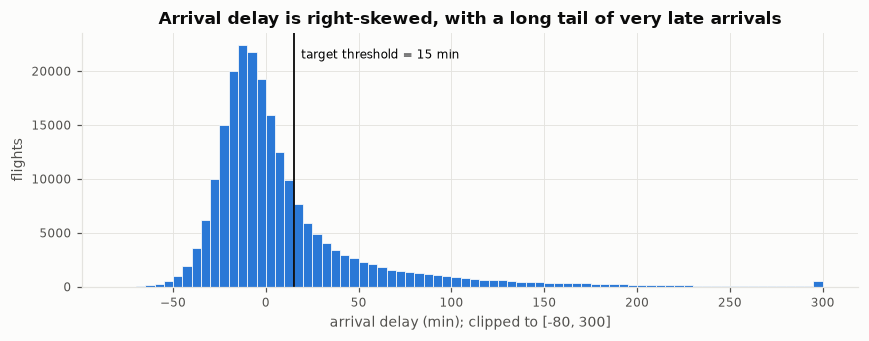

{'count': 217727.0, 'mean': 9.0, 'std': 47.3, 'min': -86.0, '25%': -16.0, '50%': -4.0, '75%': 16.0, 'max': 1272.0}
skewness: 3.53


,share of labelled flights
early (arr_delay < 0),56.0%
exactly on schedule (= 0),1.6%
"late, under threshold (0 < arr_delay < 15)",16.0%
delayed (arr_delay >= 15) — target = 1,26.4%


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
clipped = df["arr_delay"].clip(-80, 300)
ax.hist(clipped, bins=np.arange(-80, 305, 5), color=ACCENT, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(THRESHOLD, color=INK, lw=1.2)
ax.text(THRESHOLD + 4, ax.get_ylim()[1] * 0.9, f"target threshold = {THRESHOLD} min", fontsize=8)
ax.set_xlabel("arrival delay (min); clipped to [-80, 300]")
ax.set_ylabel("flights")
ax.set_title("Arrival delay is right-skewed, with a long tail of very late arrivals")
plt.tight_layout()
plt.show()
print(df["arr_delay"].describe().round(1).to_dict())
print("skewness:", round(df["arr_delay"].skew(), 2))

d = df["arr_delay"]
shares = pd.Series({
    "early (arr_delay < 0)": (d < 0).mean(),
    "exactly on schedule (= 0)": (d == 0).mean(),
    "late, under threshold (0 < arr_delay < 15)": ((d > 0) & (d < THRESHOLD)).mean(),
    f"delayed (arr_delay >= {THRESHOLD}) — target = 1": (d >= THRESHOLD).mean(),
}, name="share of labelled flights")
shares.map("{:.1%}".format).to_frame()

## 2. Airline

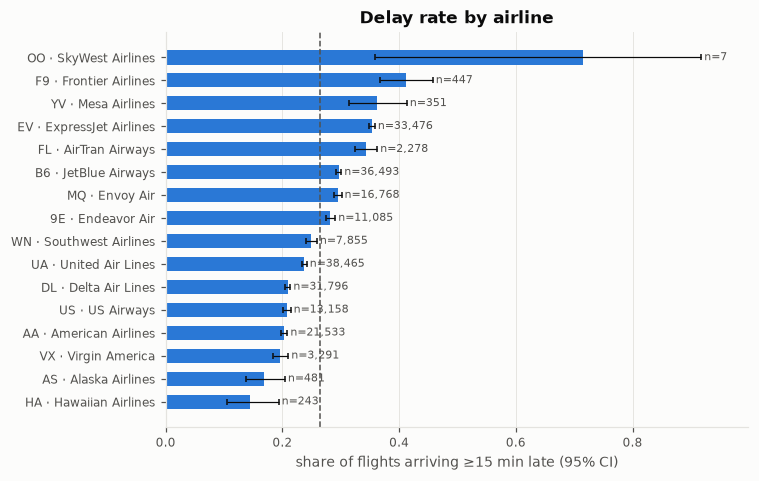

,carrier,name,n,delay_rate,ci_low,ci_high
10,OO,SkyWest Airlines Inc.,7,0.714,0.359,0.918
6,F9,Frontier Airlines Inc.,447,0.412,0.367,0.458
15,YV,Mesa Airlines Inc.,351,0.362,0.313,0.413
5,EV,ExpressJet Airlines Inc.,33476,0.353,0.348,0.359
7,FL,AirTran Airways Corporation,2278,0.343,0.324,0.363
3,B6,JetBlue Airways,36493,0.296,0.292,0.301
9,MQ,Envoy Air,16768,0.294,0.288,0.301
0,9E,Endeavor Air Inc.,11085,0.282,0.274,0.291
14,WN,Southwest Airlines Co.,7855,0.250,0.240,0.259
11,UA,United Air Lines Inc.,38465,0.238,0.233,0.242


In [4]:
car = rate_table(df, ["carrier", "name"]).reset_index()
car["label"] = car["carrier"] + " · " + car["name"].str.replace(r" (Inc\.|Co\.|Corporation|Corp)\.?$", "", regex=True)
rate_barh(car, "Delay rate by airline", label_col="label")
plt.tight_layout()
plt.show()
car.sort_values("delay_rate", ascending=False)[["carrier", "name", "n", "delay_rate", "ci_low", "ci_high"]].round(3)

## 3. Airports

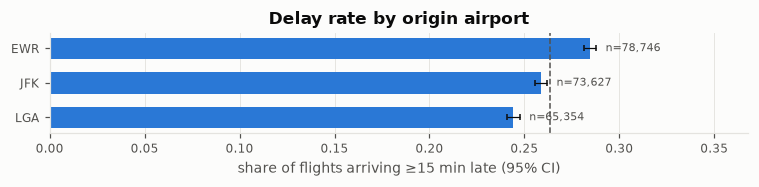

,n,n_delayed,delay_rate,ci_low,ci_high
origin,,,,,
EWR,78746,22411,0.285,0.281,0.288
JFK,73627,19050,0.259,0.256,0.262
LGA,65354,15962,0.244,0.241,0.248


In [5]:
org = rate_table(df, "origin")
rate_barh(org, "Delay rate by origin airport", height=1.8)
plt.tight_layout()
plt.show()
org.round(3)

102 destinations; 12 have < 100 labelled flights


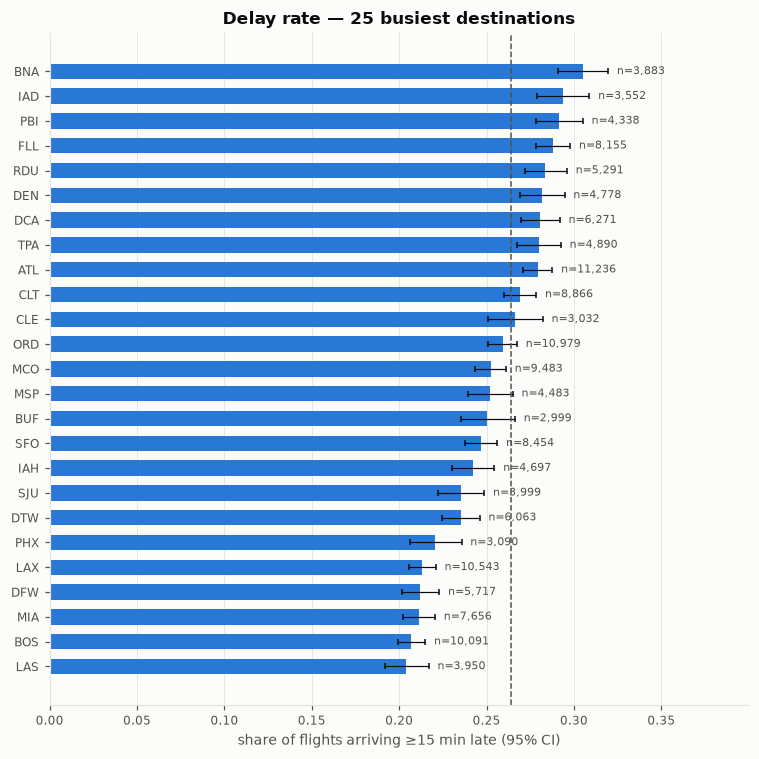

In [6]:
dest_all = rate_table(df, "dest")
print(f"{len(dest_all)} destinations; {(dest_all['n'] < 100).sum()} have < 100 labelled flights")
top_dest = dest_all.nlargest(25, "n")
rate_barh(top_dest, "Delay rate — 25 busiest destinations")
plt.tight_layout()
plt.show()

In [7]:
# Extremes among destinations with enough data (n >= 1,000)
big = dest_all[dest_all["n"] >= 1000].sort_values("delay_rate")
pd.concat([big.head(5), big.tail(5)]).round(3)

,n,n_delayed,delay_rate,ci_low,ci_high
dest,,,,,
LAS,3950,806,0.204,0.192,0.217
BOS,10091,2088,0.207,0.199,0.215
SLC,1657,343,0.207,0.188,0.227
MIA,7656,1617,0.211,0.202,0.220
DFW,5717,1213,0.212,0.202,0.223
PHL,1096,349,0.318,0.292,0.347
CVG,2463,833,0.338,0.320,0.357
MCI,1293,449,0.347,0.322,0.374
JAX,1710,599,0.350,0.328,0.373


## 4. Routes

218 routes; median labelled flights per route: 563


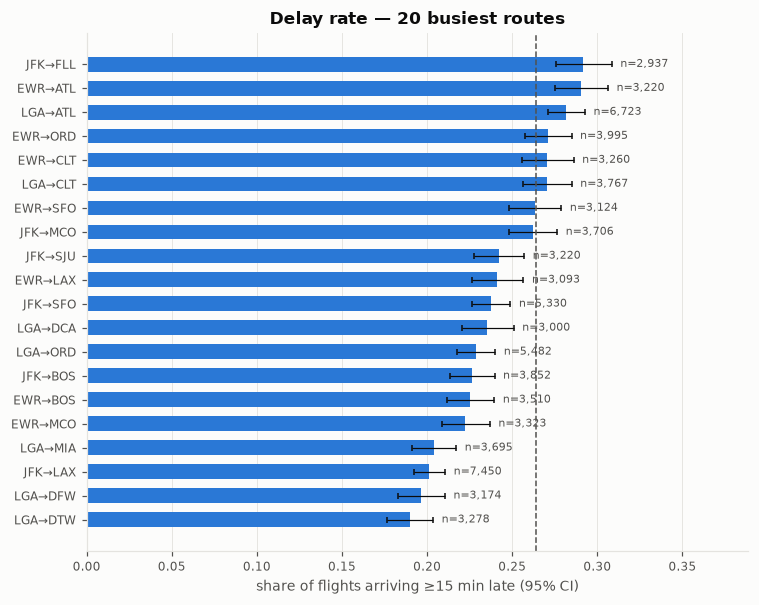

In [8]:
routes = rate_table(df, "route")
print(f"{len(routes)} routes; median labelled flights per route: {routes['n'].median():.0f}")
rate_barh(routes.nlargest(20, "n"), "Delay rate — 20 busiest routes")
plt.tight_layout()
plt.show()

In [9]:
# Same destination, different NYC origin: does the origin change the rate?
top_d = df["dest"].value_counts().head(6).index
pivot = (rate_table(df[df["dest"].isin(top_d)], ["dest", "origin"])["delay_rate"]
         .unstack("origin").round(3))
pivot

origin,EWR,JFK,LGA
dest,,,
ATL,0.290,0.238,0.282
BOS,0.225,0.226,0.156
CLT,0.271,0.264,0.271
LAX,0.241,0.201,NaN
MCO,0.222,0.262,0.278
ORD,0.271,0.339,0.229


## 5. Scheduled departure hour

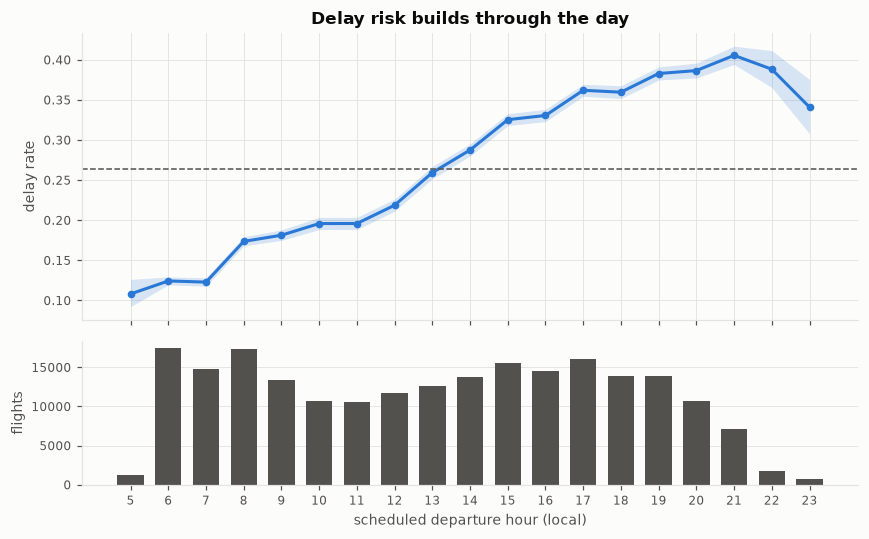

hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,1295.000,17434.000,14822.000,17294.000,13414.000,10647.000,10511.000,11730.000,12675.000,13757.000,15591.000,14473.000,16077.000,13877.00,13869.000,10654.000,7125.000,1731.000,751.000
delay_rate,0.108,0.124,0.123,0.174,0.181,0.196,0.196,0.219,0.259,0.287,0.325,0.331,0.362,0.36,0.383,0.387,0.405,0.388,0.341


In [10]:
hr = rate_table(df, "hour")
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.fill_between(hr.index, hr["ci_low"], hr["ci_high"], color=ACCENT, alpha=0.18, lw=0)
ax.plot(hr.index, hr["delay_rate"], color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(BASE, color=MUTED, ls="--", lw=1)
ax.set_ylabel("delay rate")
ax.set_title("Delay risk builds through the day")
axes[1].bar(hr.index, hr["n"], color=MUTED, width=0.7)
axes[1].set_ylabel("flights")
axes[1].set_xlabel("scheduled departure hour (local)")
axes[1].grid(axis="x", visible=False)
axes[1].set_xticks(range(5, 24))
plt.tight_layout()
plt.show()
hr[["n", "delay_rate"]].T.round(3)

## 6. Month and day of week

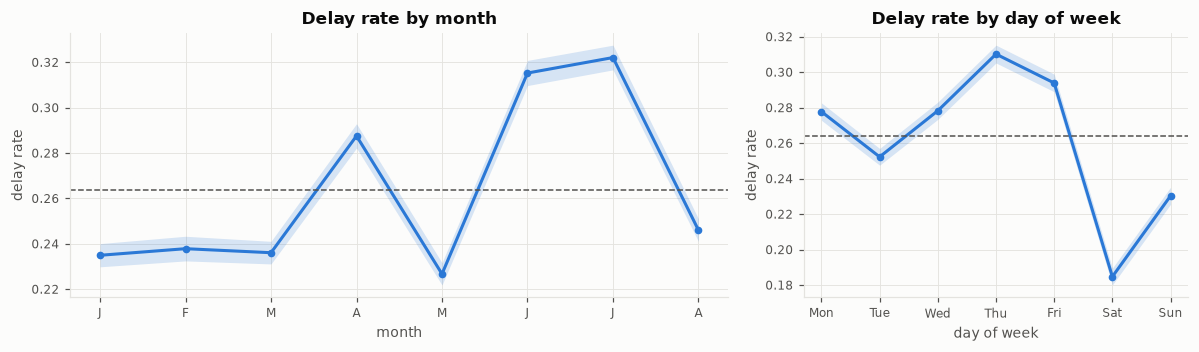

month,1,2,3,4,5,6,7,8
n,26398.000,23611.000,27902.000,27564.000,28128.000,27075.000,28293.000,28756.000
delay_rate,0.235,0.238,0.236,0.288,0.227,0.315,0.322,0.246


In [11]:
mo = rate_table(df, "month")
dw = rate_table(df, "dow")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [12, 7]})
for ax, t, xl, ticks in [
    (axes[0], mo, "month", ["JFMAMJJASOND"[m - 1] for m in mo.index]),
    (axes[1], dw, "day of week", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]),
]:
    ax.fill_between(t.index, t["ci_low"], t["ci_high"], color=ACCENT, alpha=0.18, lw=0)
    ax.plot(t.index, t["delay_rate"], color=ACCENT, lw=2, marker="o", ms=4)
    ax.axhline(BASE, color=MUTED, ls="--", lw=1)
    ax.set_xticks(t.index, ticks)
    ax.set_xlabel(xl)
    ax.set_ylabel("delay rate")
axes[0].set_title("Delay rate by month")
axes[1].set_title("Delay rate by day of week")
plt.tight_layout()
plt.show()
mo[["n", "delay_rate"]].T.round(3)

In [12]:
dw[["n", "delay_rate"]].T.round(3)

dow,0,1,2,3,4,5,6
n,32028.000,32615.000,32558.000,32663.00,32391.000,25808.000,29664.00
delay_rate,0.278,0.252,0.278,0.31,0.294,0.185,0.23


## 7. Interactions

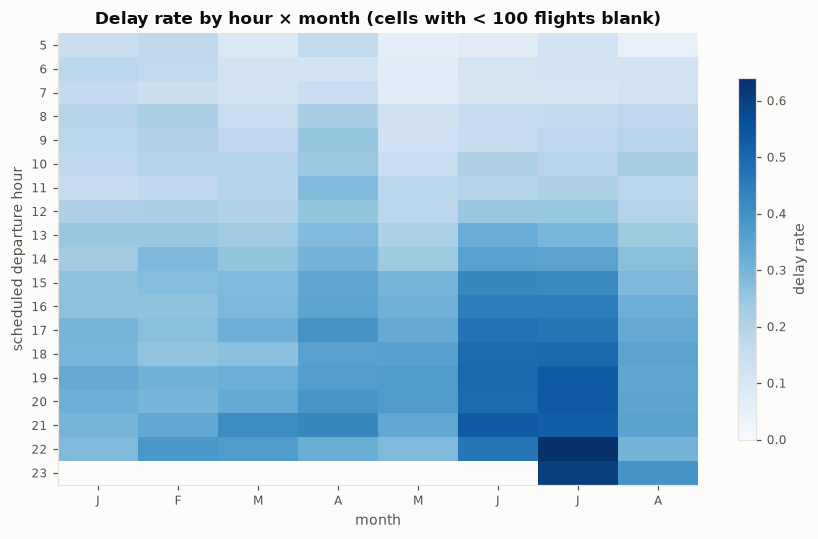

In [13]:
heat = df.pivot_table(index="hour", columns="month", values="is_delayed", aggfunc="mean")
counts = df.pivot_table(index="hour", columns="month", values="is_delayed", aggfunc="size")
heat = heat.where(counts >= 100)  # hide thin cells

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(heat.values))
ax.set_xticks(range(len(heat.columns)), ["JFMAMJJASOND"[m - 1] for m in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("month")
ax.set_ylabel("scheduled departure hour")
ax.set_title("Delay rate by hour × month (cells with < 100 flights blank)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="delay rate", shrink=0.8)
plt.tight_layout()
plt.show()

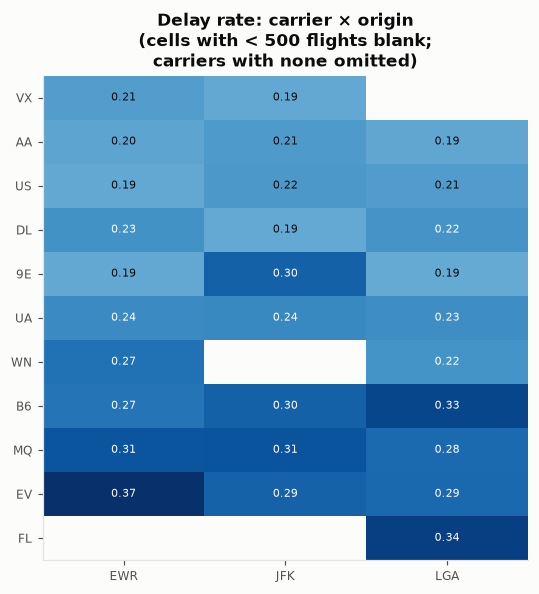

origin,EWR,JFK,LGA
carrier,,,
VX,0.209,0.192,NaN
AA,0.197,0.215,0.194
US,0.191,0.218,0.210
DL,0.227,0.190,0.223
9E,0.191,0.295,0.189
UA,0.238,0.240,0.233
WN,0.273,NaN,0.224
B6,0.269,0.295,0.333
MQ,0.313,0.314,0.284


In [14]:
co = df.pivot_table(index="carrier", columns="origin", values="is_delayed", aggfunc="mean")
cn = df.pivot_table(index="carrier", columns="origin", values="is_delayed", aggfunc="size")
co = co.where(cn >= 500).dropna(how="all")  # drop carriers with no cell >= 500
co = co.loc[co.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(5, 5.5))
im = ax.imshow(co.values, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(co.values))
for i in range(co.shape[0]):
    for j in range(co.shape[1]):
        v = co.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * np.nanmax(co.values) else INK)
ax.set_xticks(range(co.shape[1]), co.columns)
ax.set_yticks(range(co.shape[0]), co.index)
ax.set_title("Delay rate: carrier × origin\n(cells with < 500 flights blank;\ncarriers with none omitted)")
ax.grid(False)
plt.tight_layout()
plt.show()
co.round(3)


## 8. Temporal dependence

If bad days cluster, recent delay history is informative — which motivates the
*past-dates-only* historical features in the feature-engineering stage.

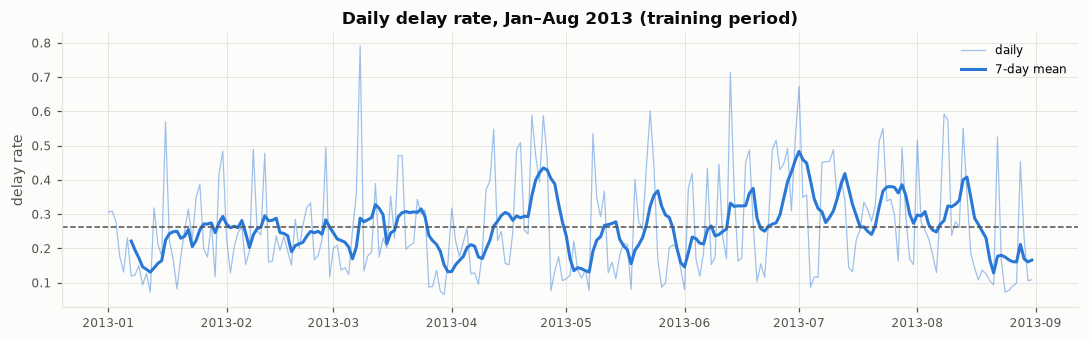

autocorrelation of daily delay rate at lag 1: 0.356
autocorrelation of daily delay rate at lag 2: 0.041
autocorrelation of daily delay rate at lag 7: 0.021
days with delay rate > 50%: 19


,n,rate
date,,
2013-03-08,798,0.792
2013-06-13,881,0.714
2013-07-01,877,0.673
2013-05-23,756,0.602
2013-08-08,929,0.592


In [15]:
daily = df.groupby("date").agg(n=("is_delayed", "size"), rate=("is_delayed", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily["rate"], color=ACCENT, lw=0.8, alpha=0.45, label="daily")
ax.plot(daily.index, daily["rate"].rolling(7).mean(), color=ACCENT, lw=2, label="7-day mean")
ax.axhline(BASE, color=MUTED, ls="--", lw=1)
ax.set_ylabel("delay rate")
ax.set_title("Daily delay rate, Jan–Aug 2013 (training period)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

for lag in [1, 2, 7]:
    print(f"autocorrelation of daily delay rate at lag {lag}: {daily['rate'].autocorr(lag):.3f}")
print("days with delay rate > 50%:", int((daily["rate"] > 0.5).sum()))
daily.nlargest(5, "rate").round(3)

## 9. Scheduled congestion and distance

In [16]:
# Scheduled departures per origin per hour, counted on the full raw schedule (see setup cell)
print("rows with all-flights count > labelled-only count:",
      int((df["sched_dep_per_origin_hour"] > df.groupby(CONGESTION_KEYS)["id"].transform("size")).sum()),
      f"of {len(df):,}")
df["congestion_bin"] = pd.qcut(df["sched_dep_per_origin_hour"], 5, duplicates="drop")
cong = rate_table(df, "congestion_bin")
print("Spearman ρ (hourly scheduled departures, delayed):",
      round(df[["sched_dep_per_origin_hour", "is_delayed"]].corr("spearman").iloc[0, 1], 3))
top_hours = (df.groupby("congestion_bin", observed=True)["hour"]
             .agg(lambda s: ", ".join(f"{h}:00 {p:.0%}" for h, p in s.value_counts(normalize=True).head(3).items())))
display(top_hours.to_frame("three most common scheduled hours"))
cong.round(3)

rows with all-flights count > labelled-only count: 60302 of 217,727
Spearman ρ (hourly scheduled departures, delayed): 0.014


,three most common scheduled hours
congestion_bin,
"(0.999, 16.0]","10:00 14%, 21:00 14%, 12:00 12%"
"(16.0, 19.0]","9:00 15%, 14:00 12%, 6:00 11%"
"(19.0, 22.0]","18:00 16%, 16:00 11%, 7:00 10%"
"(22.0, 25.0]","15:00 16%, 17:00 14%, 19:00 12%"
"(25.0, 38.0]","6:00 25%, 8:00 23%, 17:00 13%"


,n,n_delayed,delay_rate,ci_low,ci_high
congestion_bin,,,,,
"(0.999, 16.0]",48018,11254,0.234,0.231,0.238
"(16.0, 19.0]",43319,11138,0.257,0.253,0.261
"(19.0, 22.0]",50154,14923,0.298,0.294,0.302
"(22.0, 25.0]",34203,10178,0.298,0.293,0.302
"(25.0, 38.0]",42033,9930,0.236,0.232,0.240


In [17]:
df["distance_bin"] = pd.qcut(df["distance"], 10, duplicates="drop")
dist = rate_table(df, "distance_bin")
dist.round(3)

,n,n_delayed,delay_rate,ci_low,ci_high
distance_bin,,,,,
"(79.999, 214.0]",22545,5718,0.254,0.248,0.259
"(214.0, 427.0]",21855,6380,0.292,0.286,0.298
"(427.0, 544.0]",21004,5643,0.269,0.263,0.275
"(544.0, 738.0]",22230,6318,0.284,0.278,0.290
"(738.0, 888.0]",21620,6420,0.297,0.291,0.303
"(888.0, 1028.0]",22348,5995,0.268,0.262,0.274
"(1028.0, 1096.0]",22241,5641,0.254,0.248,0.259
"(1096.0, 1598.0]",21996,5596,0.254,0.249,0.260
"(1598.0, 2446.0]",20570,4740,0.230,0.225,0.236


## 10. Congestion within the same departure hour

The overall congestion association is confounded with departure hour: the busiest slots are
early-morning banks, which have low delay rates. Comparing slots *within the same scheduled
hour* removes that confounder (origin and date mix still differ).

In [18]:
rows = []
for h, g in df.groupby("hour"):
    if len(g) < 1000:
        continue
    c = g["sched_dep_per_origin_hour"]
    rows.append({
        "hour": h, "n": len(g),
        "spearman": g[["sched_dep_per_origin_hour", "is_delayed"]].corr("spearman").iloc[0, 1],
        "rate_lowest_third": g.loc[c <= c.quantile(1 / 3), "is_delayed"].mean(),
        "rate_highest_third": g.loc[c >= c.quantile(2 / 3), "is_delayed"].mean(),
    })
within = pd.DataFrame(rows).set_index("hour")
within["difference"] = within["rate_highest_third"] - within["rate_lowest_third"]
print("flight-weighted mean within-hour Spearman:",
      round(np.average(within["spearman"], weights=within["n"]), 3))
print("hours where busier slots are more delayed:", int((within["difference"] > 0).sum()), "of", len(within))
within.round(3)


flight-weighted mean within-hour Spearman: 0.05
hours where busier slots are more delayed: 15 of 18


,n,spearman,rate_lowest_third,rate_highest_third,difference
hour,,,,,
5,1295,-0.008,0.105,0.103,-0.002
6,17434,-0.007,0.127,0.132,0.005
7,14822,0.068,0.096,0.144,0.048
8,17294,0.041,0.149,0.180,0.031
9,13414,0.021,0.177,0.193,0.017
10,10647,0.052,0.179,0.203,0.024
11,10511,0.052,0.183,0.238,0.054
12,11730,0.060,0.197,0.238,0.041
13,12675,0.069,0.211,0.291,0.080


## 11. Holiday proximity

The feature set includes US federal holiday proximity (`is_holiday`, `days_from_holiday`).
Within the training period there are only five holidays (listed below), so this is weak evidence
either way.

In [19]:
from flight_delay.features.calendar import add_calendar_features, us_federal_holidays

print("federal holidays in the EDA period:",
      [d.strftime("%Y-%m-%d") for d in us_federal_holidays(TRAIN_START, TRAIN_END)])
cal = add_calendar_features(df[["date", "sched_dep_dt"]])
df["holiday_distance"] = pd.cut(cal["abs_days_to_holiday"], [-1, 0, 3, 7, 13, 14],
                                 labels=["holiday", "1-3 days", "4-7 days", "8-13 days", "14+ days"])
rate_table(df, "holiday_distance").round(3)


federal holidays in the EDA period: ['2013-01-01', '2013-01-21', '2013-02-18', '2013-05-27', '2013-07-04']


,n,n_delayed,delay_rate,ci_low,ci_high
holiday_distance,,,,,
holiday,4332,780,0.180,0.169,0.192
1-3 days,25267,6262,0.248,0.243,0.253
4-7 days,35176,10356,0.294,0.290,0.299
8-13 days,46356,10654,0.230,0.226,0.234
14+ days,106596,29371,0.276,0.273,0.278


Note: congestion counts **all scheduled departures** in the origin/date/hour slot from the raw
table, including flights that were later cancelled or have no arrival-delay label. The count is
computed before the missing-label policy is applied, so it reflects the published schedule rather
than only the flights that kept a label. It is a descriptive, hour-level association and is
confounded with departure hour (busy banks are concentrated in particular times of day).

## Findings (training period, Jan–Aug 2013)

All rates below are for the **217,727 training-period flights** with an observed arrival-delay label (`exclude` policy); overall delay rate **26.4%**. Validation (Sep–Oct) and test (Nov–Dec) outcomes were not used.
**Scope:** the model predicts arrival delay ≥ 15 min *for flights with an observed arrival-delay label*. It does not predict cancellations or diversions.
**Interpretation:** every comparison below is descriptive. Confidence intervals assume independent flights, which understates uncertainty given same-day clustering (item 7), and group differences may reflect the route, carrier, hour and month mix rather than the grouping variable itself.

0. **Arrival-delay distribution.** 56.0% of labelled flights arrive before schedule, 1.6% exactly on schedule, 16.0% late by under 15 min, and 26.4% late by 15 min or more (target = 1). The distribution is right-skewed (skewness 3.53; 99th percentile 201 min).
1. **Time of day shows the clearest gradient.** The delay rate rises almost monotonically from 10.8% for 05:00 departures to 40.5% at 21:00, then falls (38.8% at 22:00, 34.1% at 23:00, on far fewer flights). This is consistent with delays propagating through the day.
2. **Seasonality within the training period.** Monthly rates range from 22.7% (May) to 32.2% (July), with June 31.5% and April 28.8%. The level shifts from month to month, so a fixed month effect learned on Jan–Aug cannot be assumed for later months.
3. **Day of week:** Thursday is worst (31.0%) and Saturday best (18.5%; Sunday 23.0%). Saturday also has the fewest flights (25,808 vs ~32k on weekdays).
4. **Observed delay rates vary across airlines.** Among carriers with large samples, ExpressJet (EV, 35.3%, n = 33,476), JetBlue (B6, 29.6%) and Envoy (MQ, 29.4%) are highest; Delta (20.9%), US Airways (20.7%) and American (20.3%) are lowest. Frontier (41.2%), Mesa (36.2%) and AirTran (34.3%) are also high on smaller samples. SkyWest (OO) has 7 labelled flights and should not be interpreted. Carriers differ in routes, hubs and departure times, so these gaps are not a like-for-like punctuality ranking.
5. **Origin airport:** EWR 28.5%, JFK 25.9%, LGA 24.4%. The carrier × origin table shows the origin effect is **not uniform** across carriers: 9E is 19.1% at EWR but 29.5% at JFK; EV is 36.5% at EWR vs 29.4% (JFK) and 28.6% (LGA); B6 is 33.3% at LGA vs 26.9% at EWR; DL is lowest at JFK (19.0%). This suggests interactions that a purely additive model may miss.
6. **Destinations and routes:** among destinations with ≥ 1,000 flights, rates range from 20.4% (LAS) to 41.4% (RIC). There are 218 routes (median 563 flights each). The same destination can differ by origin, e.g. ORD: JFK 33.9% vs LGA 22.9%; BOS: LGA 15.6% vs EWR/JFK ~22.5%. 12 of 102 destinations have < 100 flights, so per-destination statistics need smoothing or a minimum count.
7. **Delays cluster from one day to the next, but not beyond.** The daily delay rate has lag-1 autocorrelation **0.356**, but lag-2 is only 0.041 and lag-7 0.021. 19 days have more than half of flights delayed (worst: 2013-03-08 at 79%). Yesterday's delays are informative; day-to-day persistence over a week is not visible in the daily rate.
8. **Scheduled congestion: flat overall, weakly positive within the same hour.** Across quintiles the delay rate is 23.4%, 25.7%, 29.8%, 29.8%, 23.6% (overall Spearman ρ 0.014). The busiest quintile is mostly 06:00 and 08:00 banks, which have low delay rates, so the overall figure is confounded with hour. Within the same scheduled hour, busier slots are more delayed in 15 of 18 hours (flight-weighted Spearman 0.05), most clearly in the evening (20:00–22:00: +14 to +18 points between the busiest and quietest third). Counts use the full schedule including later-cancelled flights (60,302 of 217,727 rows have a higher count than a labelled-only count would give).
9. **Distance has a weak, non-monotonic relationship** with delay: 23.0–29.7% across deciles, lowest for the longest flights (> 1,598 mi: ~23%).
10. **Holiday proximity is inconclusive.** The period contains five federal holidays. Holiday dates have a lower rate (18.0%, n = 4,332) than days 14+ from a holiday (27.6%), but the pattern is not monotonic (1–3 days 24.8%, 4–7 days 29.4%, 8–13 days 23.0%) and rests on five dates whose neighbourhoods coincide with high-delay summer weeks.

## Comparison with the earlier full-year EDA

The earlier version of this notebook used all twelve months, including validation and test outcomes. On the training period alone:

| Pattern | Full year (earlier) | Jan–Aug (this version) | Conclusion |
|---|---|---|---|
| Hour gradient, 05:00 → 21:00 | 10.5% → 37.4% | 10.8% → 40.5% | Same |
| Weekday: worst / best | Thu 28.5% / Sat 17.5% | Thu 31.0% / Sat 18.5% | Same |
| Carrier × origin non-uniform | 9E: EWR 16% vs JFK 27% | 9E: EWR 19.1% vs JFK 29.5% | Same |
| Daily autocorrelation, lag 1 / 2 / 7 | 0.40 / 0.13 / 0.11 | 0.356 / 0.041 / 0.021 | **Lag 1 same; lags 2 and 7 not supported** |
| Congestion, overall | non-monotonic, ρ 0.009 | non-monotonic, ρ 0.014 | Same (within-hour check added) |
| Distance | weak, 22–28% | weak, 23–30% | Same |
| Seasonality | Dec highest (33.6%) | July highest (32.2%) | Test months no longer visible |

## Implications for feature engineering (decided in Phase 3, D-102)
- **Supported by training data:** scheduled hour (and its cyclic encoding), departure-time bucket, day of week and weekend; carrier, origin, destination and route; carrier × origin crosses; the 1-day history window.
- **Weak or indirect support:** congestion (weak within-hour association), distance and other schedule features (weak), 7- and 28-day history windows (no daily autocorrelation beyond lag 1; month-level shifts within Jan–Aug and per-key base-rate differences are the remaining rationale).
- **Not examined or inconclusive:** holiday proximity; origin × departure-bucket and carrier × departure-bucket crosses.
- Small groups (rare destinations, OO, HA) need minimum-count thresholds or shrinkage.

## Limitations
- These are descriptive, univariate or two-way associations, not causal effects; for example, carrier rates are partly driven by carriers' hour and route mix.
- Congestion is computed from the full raw schedule (origin × date × scheduled hour, all flights including later-cancelled ones). Since it uses only the published schedule, it is available before departure.
- Wilson intervals assume independent flights; same-day clustering makes them too narrow.
- Rates are conditional on an observed arrival-delay label; cancelled flights and flights without an arrival record are outside the prediction scope.
- Eight months of NYC departures. Each month occurs once, and the five holidays give little evidence about holiday effects.
